In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

In [2]:
pae_aggregator_scores = pd.read_csv('../data/interim/pae_aggregator_predictions.csv')

In [3]:
pae_aggregator_scores = pae_aggregator_scores.rename({'name': 'tcr_id'}, axis='columns')

In [4]:
sequences = pd.read_csv('../data/interim/sequences.csv', index_col='tcr_id')

In [5]:
pae_aggregator_scores = pae_aggregator_scores.merge(sequences, how='inner', left_on='tcr_id', right_index=True)

In [6]:
prediction_columns = [f'prediction_{i}' for i in range(1, 5 + 1)]
pae_aggregator_scores = pae_aggregator_scores.melt(
    id_vars=[column for column in pae_aggregator_scores.columns if column not in prediction_columns],
    value_vars=prediction_columns,
    var_name='prediction_number',
    value_name='prediction',
)

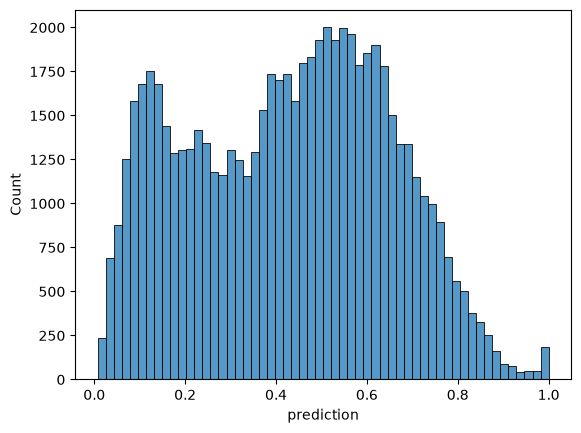

In [7]:
sns.histplot(pae_aggregator_scores, x='prediction')
plt.show()

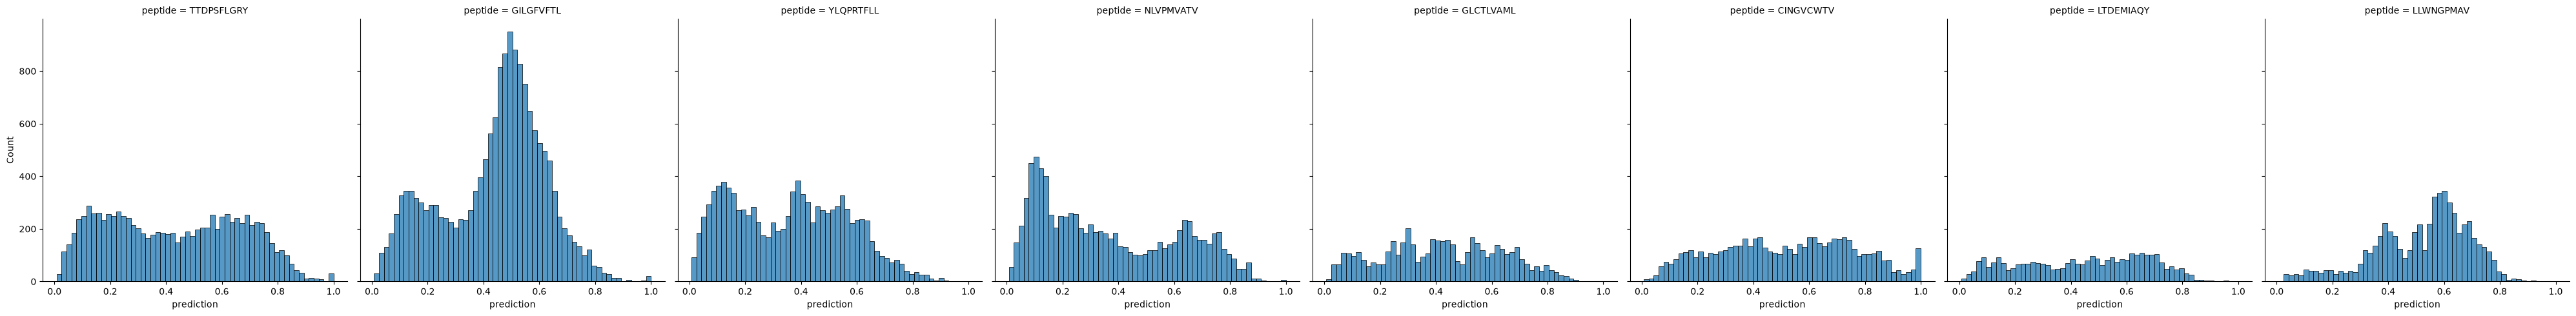

In [8]:
sns.displot(pae_aggregator_scores, x='prediction', col='peptide')
plt.show()

In [9]:
pae_aggregator_scores_agg = pae_aggregator_scores.groupby('tcr_id').agg({'prediction': 'median'})
pae_aggregator_scores_agg = pae_aggregator_scores_agg.merge(
    sequences[['peptide']], how='inner', left_index=True, right_index=True
)

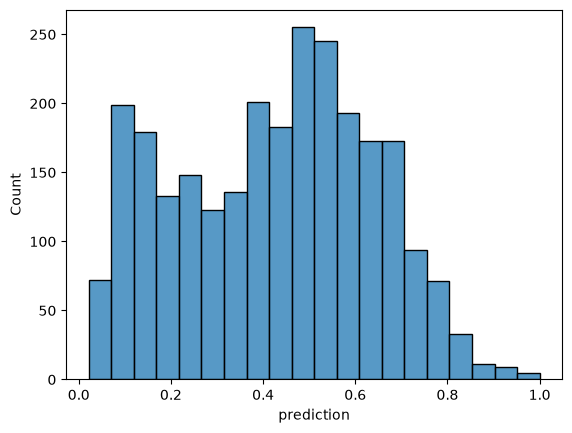

In [10]:
sns.histplot(pae_aggregator_scores_agg, x='prediction')
plt.show()

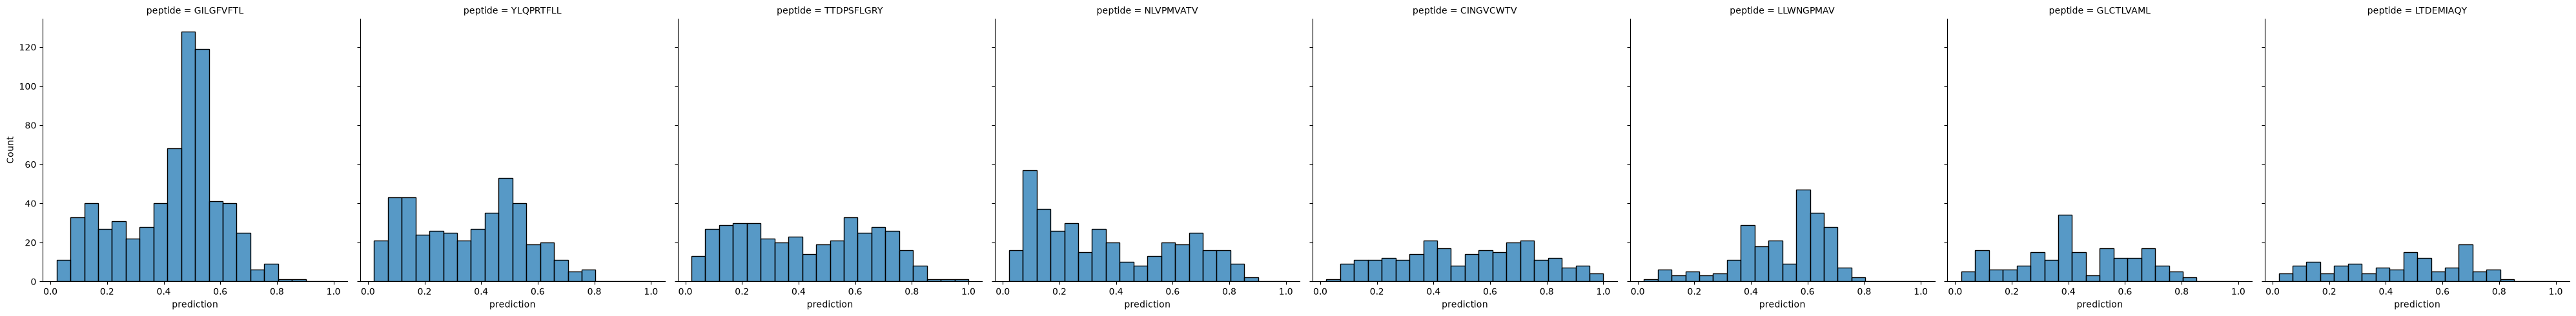

In [11]:
sns.displot(pae_aggregator_scores_agg, x='prediction', col='peptide')
plt.show()

In [12]:
public_labels = pd.read_csv('../data/external/ttd_gil_ylq_nlv_glc_01-10-2026_TCRvdb.csv', index_col='tcr_id')

In [13]:
pae_aggregator_scores_public = pae_aggregator_scores_agg.merge(
    public_labels.query('ambiguous == 0'), how='inner', left_on='tcr_id', right_index=True
)

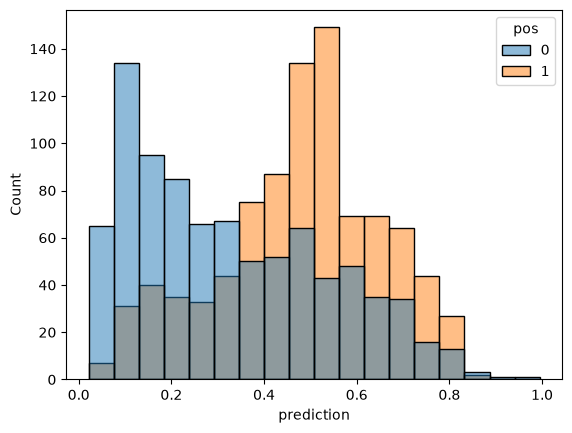

In [14]:
sns.histplot(pae_aggregator_scores_public, x='prediction', hue='pos', multiple='layer')
plt.show()

In [15]:
print('PAE Aggregator:', roc_auc_score(pae_aggregator_scores_public['pos'], pae_aggregator_scores_public['prediction']))

PAE Aggregator: 0.7108352656517795


In [16]:
per_peptide_performance = (
    pae_aggregator_scores_public.groupby('epitope_aa')
    .apply(lambda group: roc_auc_score(group['pos'], group['prediction']), include_groups=False)
    .sort_values(ascending=False)
)

print(per_peptide_performance, end='\n\n')
print('Macro-averaged ROC-AUC for combined method:', per_peptide_performance.mean())

epitope_aa
YLQPRTFLL     0.808516
NLVPMVATV     0.793786
TTDPSFLGRY    0.681703
GLCTLVAML     0.655195
GILGFVFTL     0.622358
dtype: float64

Macro-averaged ROC-AUC for combined method: 0.7123116554179816


In [17]:
pae_aggregator_scores_agg[['prediction']].to_csv('../data/processed/pae_aggregator_predictions.csv', index=True)